# Write the science. Our compilers make it fast, differentiable, and Bayesian.

Science runs on code that scientists write. Putting that code on GPUs and TPUs, or differentiating through it, normally means a rewrite by experts, often into another framework. Error bars come from running the model thousands of times, and making that fast normally means an expert hand-tunes the model. Our open-source compiler stack ([EnzymeAD](https://github.com/EnzymeAD)) does all of this automatically, on the code that already exists.

| | |
|---|---|
| **Reactant** | compiles existing code for GPUs and TPUs, and optimizes it along the way |
| **Enzyme** | differentiates entire programs written in C, C++, Fortran, Rust, Julia, or Python |
| **Impulse** | builds probabilistic programming into the compiler: write the model the way the science reads, get fast inference with uncertainty |

## Setup

In [ ]:
if any(occursin("COLAB"), keys(ENV))
    using Downloads
    tok = get(ENV, "SAIL_GITHUB_TOKEN", "")
    include(Downloads.download("https://raw.githubusercontent.com/PRONTOLab/sail2026-demo/main/colab/colab_setup.jl";
        headers = isempty(tok) ? Pair{String, String}[] : ["Authorization" => "Bearer $tok"]))
end
include("demo_utils.jl")
prepare_demo!()

## Reactant: your code, on any AI hardware

Add one line, `@jit`, and an ordinary function is compiled for the hardware you have: CPU, GPU, or TPU. Nothing is rewritten into another framework.

In [2]:
f(x) = sum(abs2, sin.(x) .* exp.(-x .^ 2))    # ordinary Julia: nothing GPU-specific

x = rand(Float32, 10_000_000)                 # ten million numbers
x_gpu = Reactant.to_rarray(x)                 # the same numbers, on the GPU

@jit f(x_gpu)                                 # the one line you add

ConcretePJRTNumber{Float32, 1}(994315.8f0)

In [3]:
cpu_vs_gpu(f, x, x_gpu)

CPU:   131.93 ms   answer 994316
GPU:     0.06 ms   answer 994316


### At supercomputer scale

[Oceananigans](https://github.com/CliMA/Oceananigans.jl) is an ocean model written in Julia for NVIDIA GPUs. Google's TPUs cannot run NVIDIA GPU code. Reactant compiled the model for TPUs and ran it on **1,280 TPU chips**, and on **4,096 NVIDIA GPUs** of NERSC's Perlmutter supercomputer ([GB-25](https://github.com/PRONTOLab/GB-25)). Spreading the same function across many devices takes two more lines:

```julia
mesh = Sharding.Mesh(reshape(Reactant.devices(), 2, 4), (:x, :y))   # 8 devices in a 2×4 grid
x = Reactant.to_rarray(data; sharding = Sharding.NamedSharding(mesh, (:x, :y)))
@jit f(x)                                                            # the same f, across all 8
```

## Enzyme: the gradient of your simulation, in one line

A gradient tells you how to change every input to improve a result. Gradients are how neural networks learn, and how scientists fit simulations to data or work backwards from what they observe to what caused it. Enzyme computes gradients of existing code.

### Example: work backwards through a simulation

Heat spreads a hidden pattern across a metal plate. This is the whole simulation, in plain code:

```julia
function simulate(u, L)
    for _ in 1:60                                  # 60 time steps of the heat equation
        u = u .+ 0.2 .* (L * u .+ u * L)
    end
    return u
end
```

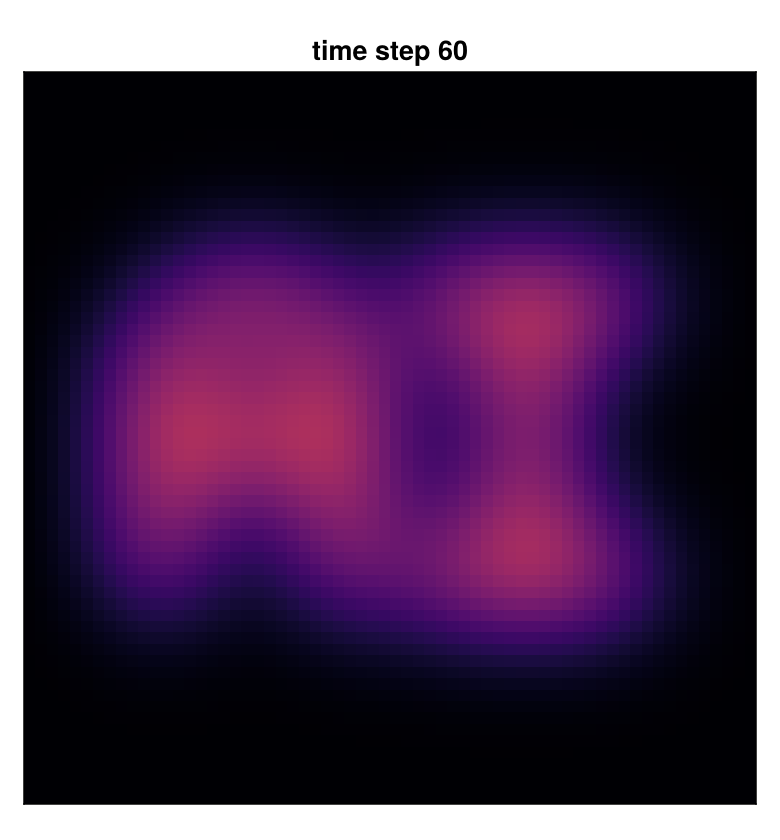

In [4]:
heat_spread!()

We see only the blur. Which starting pattern caused it? The plate has 64 × 64 = **4,096 unknown temperatures**, and every improvement to a guess needs to know how the result responds to each one.

- **Without gradients:** rerun the simulation once per unknown, 4,097 simulations per improvement.
- **With Enzyme:** one line.

```julia
loss(u0) = sum(abs2, simulate(u0, L) .- observed) + λ * edge_penalty(u0)   # mismatch, preferring sharp edges
Enzyme.gradient(Reverse, loss, u0)                                          # the one line you add
```

In [5]:
gradient_vs_rerun()

one simulation (60 time steps):              0.84 ms
with Enzyme, one gradient (all 4096):        2.75 ms  (about 3 simulations)


without gradients, 4097 simulations:        3446 ms


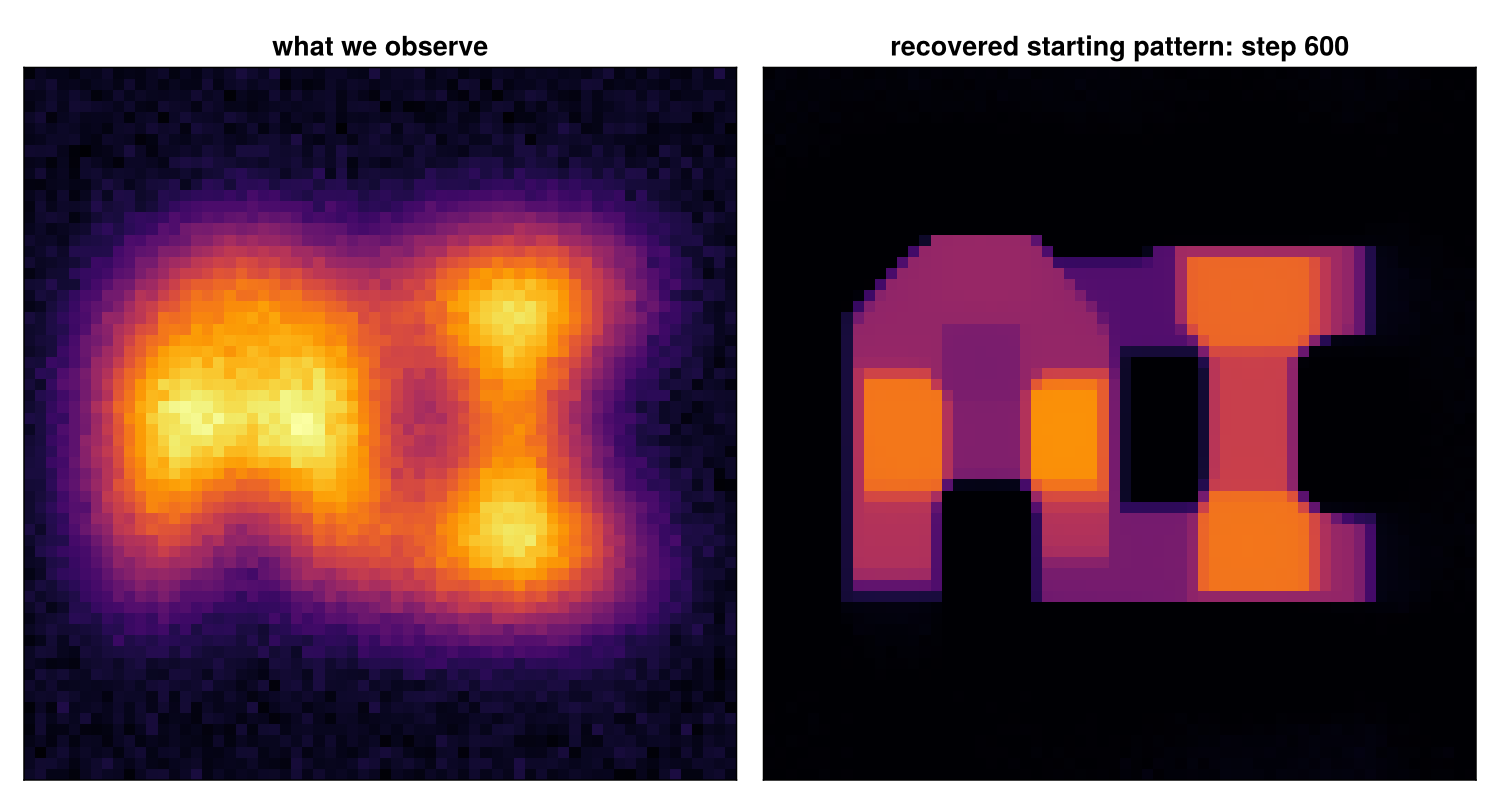

600 improvement steps with Enzyme gradients: 1.3 s
without gradients: 2.5 million simulations, about 34 minutes


In [6]:
rec = unblur!();

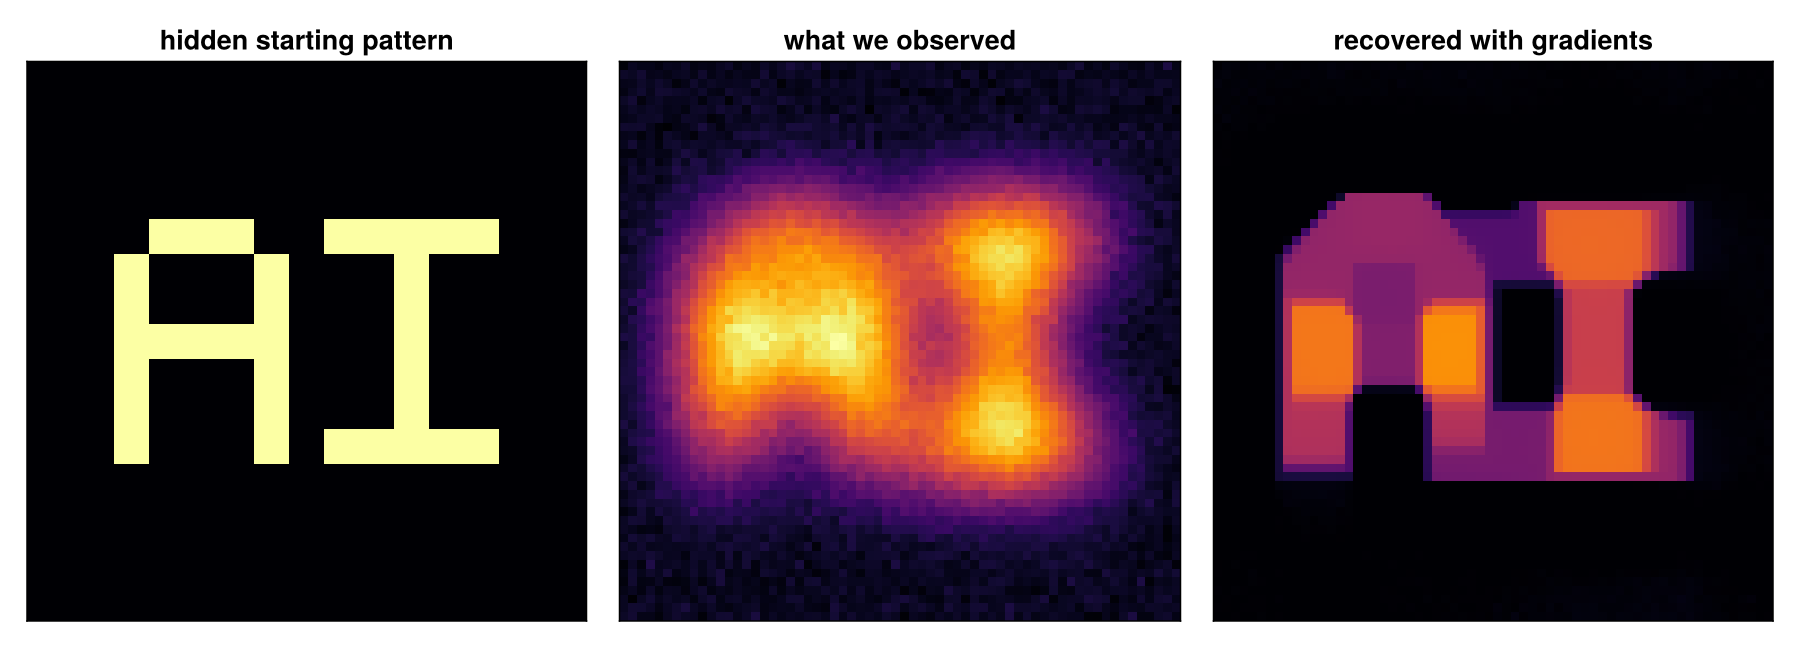

In [7]:
heat_reveal(rec)

The usual alternative is a second, hand-written "adjoint" program for every simulation. Enzyme derives it from the simulation code itself.

## Real science: imaging a black hole

In 2019 the **Event Horizon Telescope** (EHT) released the first image of a black hole, M87\*. The EHT links radio dishes across the Earth into one planet-sized telescope, but it never takes a picture: each pair of dishes measures one "ripple pattern" of the sky. Below is **every measurement** from one night in April 2017; the image has to be *inferred* from these points.

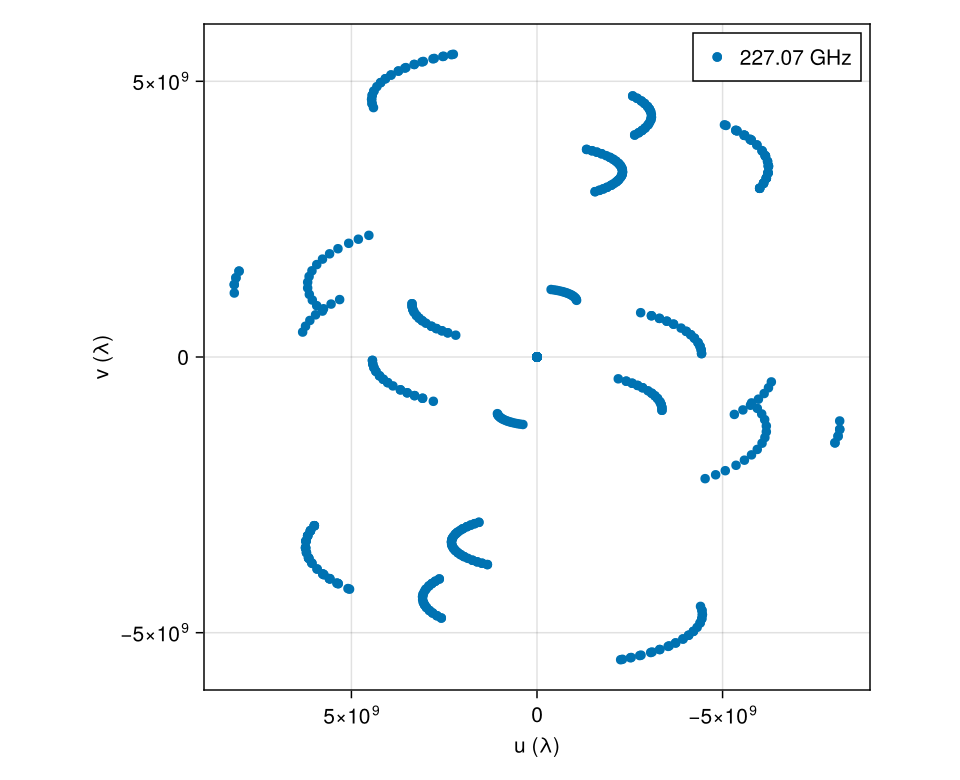

In [8]:
plotfields(dvis, :U, :V; figure_kwargs = (; size = (640, 520)))

[Comrade.jl](https://github.com/ptiede/Comrade.jl) is the EHT imaging package by Paul Tiede. Its model of the sky and of every telescope spans several libraries: **2,635 unknowns from 274 measurements**. Moving a package like this to a GPU usually means rewriting it. Our stack runs it as it is: Reactant compiles it for the GPU, and Enzyme differentiates through all of it.

First, the single best image, by gradient steps through the whole package:

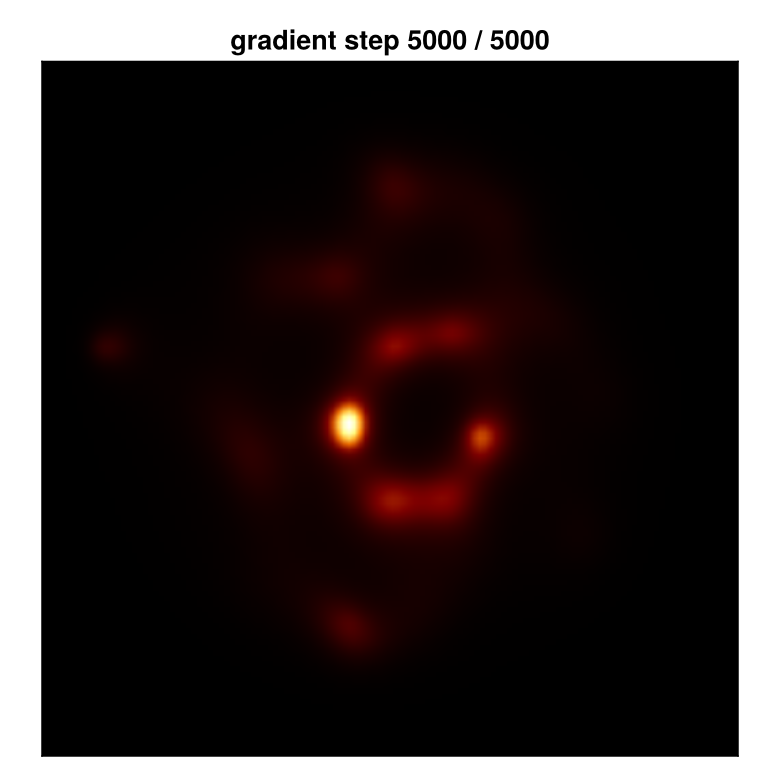

5000 gradient steps on 2635 unknowns: 1.8 s of GPU time


In [9]:
xbest = fit!(steps = 5000);

That is **one** best guess, and it is speckled. Which parts are real? With 2,635 unknowns and 274 measurements, many different images fit the data.

## Impulse: answers with uncertainty

Bayesian inference finds *all* images consistent with the data. In Comrade, switching to our sampler is one argument, and Impulse compiles the entire sampler into one GPU program:

```julia
sample(post, NUTS(0.8), 1000)          # the sampler in Comrade's tutorial
sample(post, ReactantNUTS(), 1000)     # Impulse
```

Paul Tiede's imaging pipeline, [BlackBoxComrade](https://github.com/BH-CAT/BlackBoxComrade.jl), offers the same switch in its configuration (`use_reactant = true`).

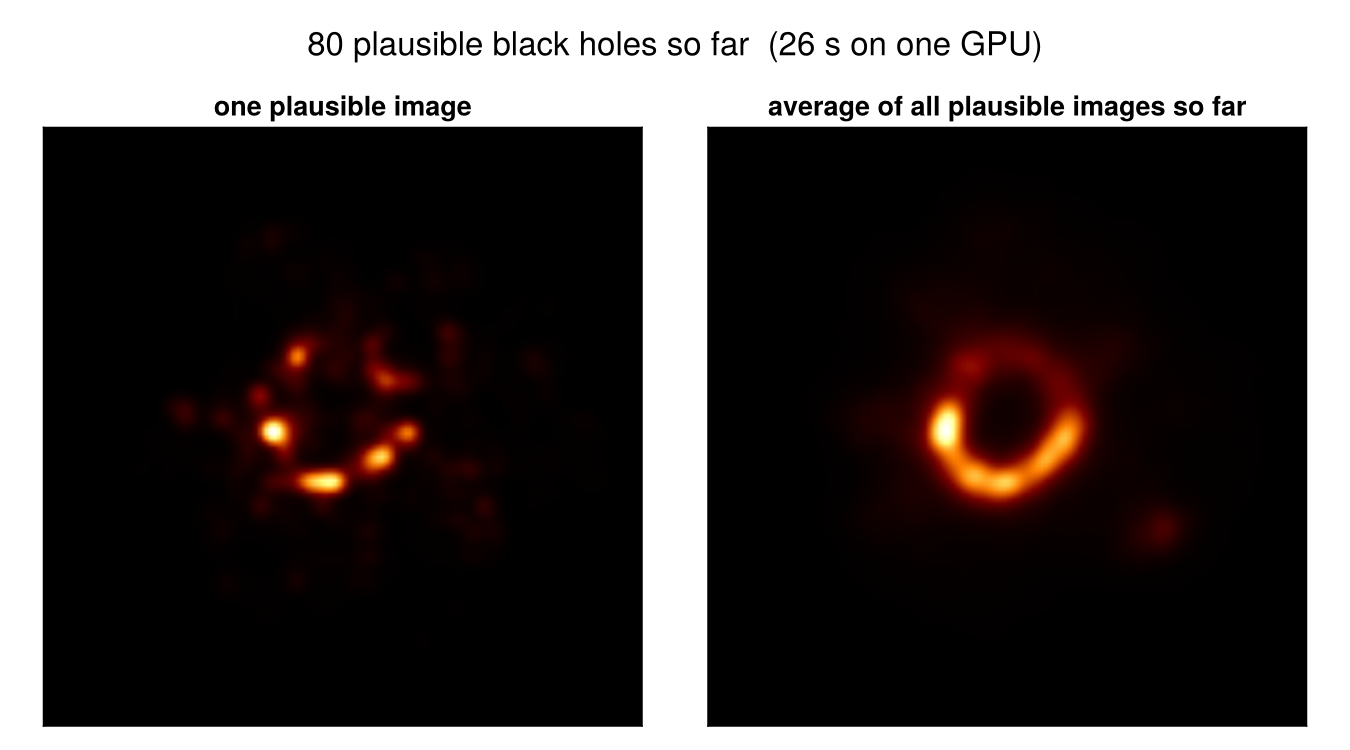

In [10]:
imgs = sample_live!(nchunks = 8);

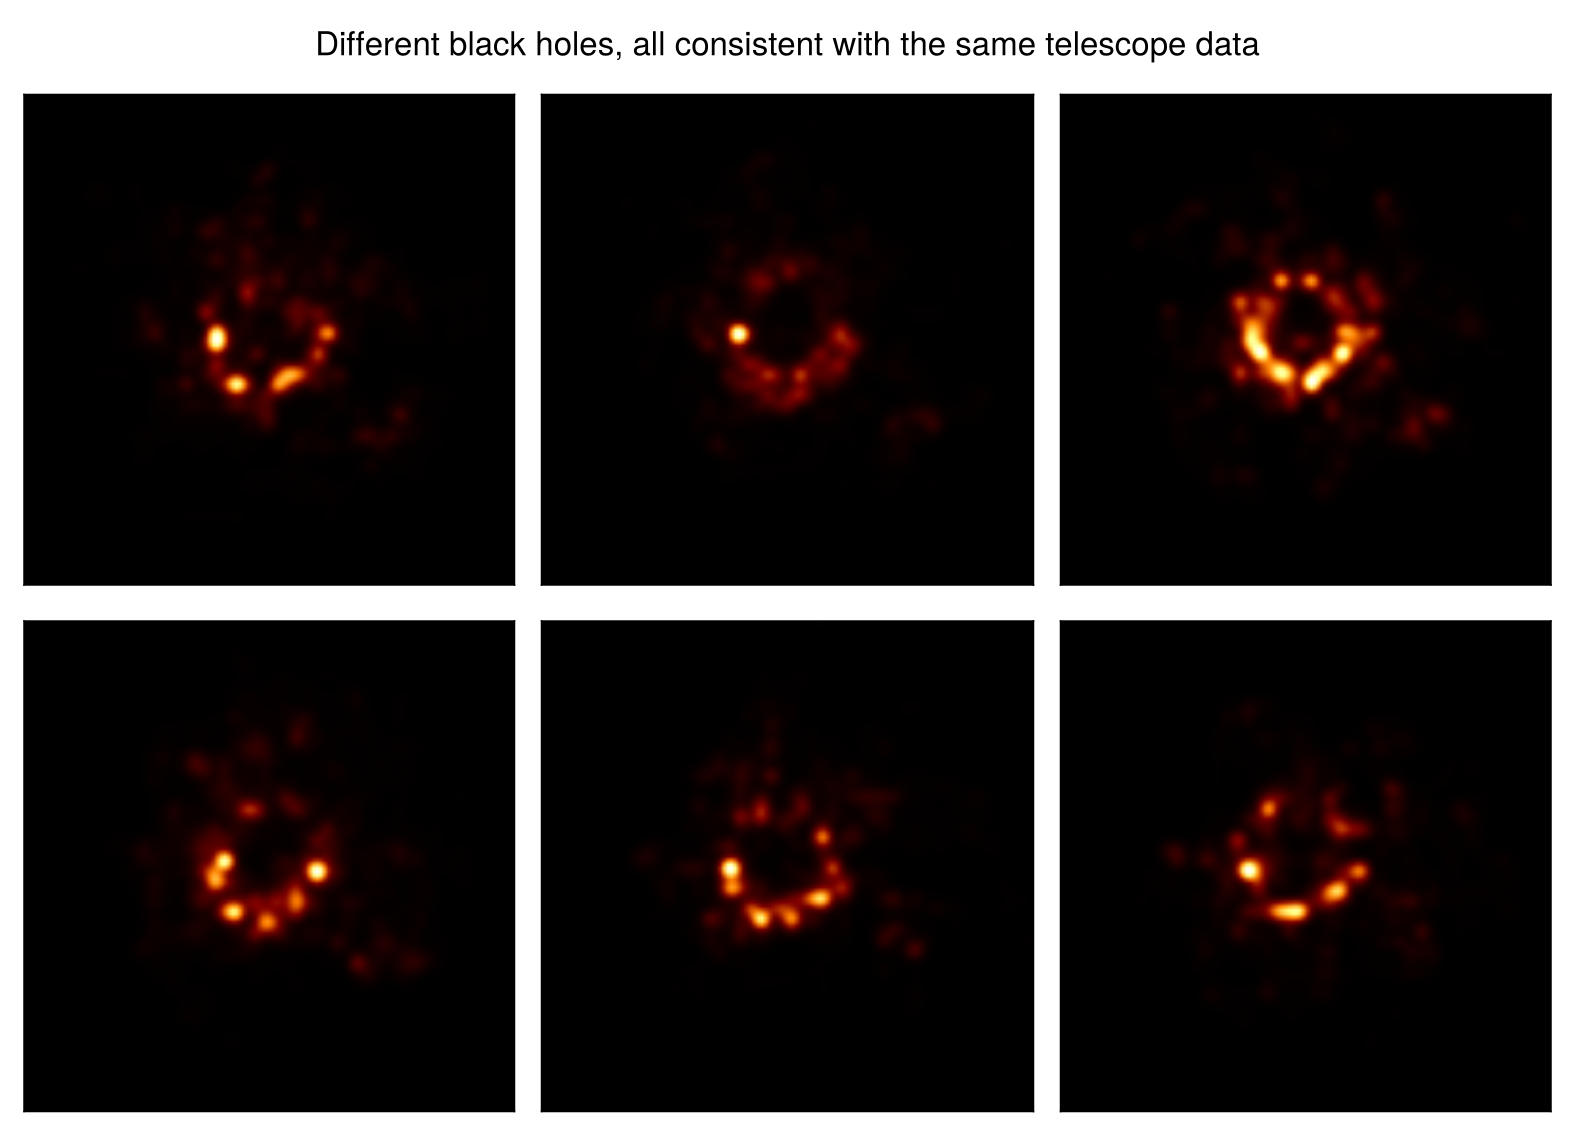

In [11]:
show_draws(imgs)

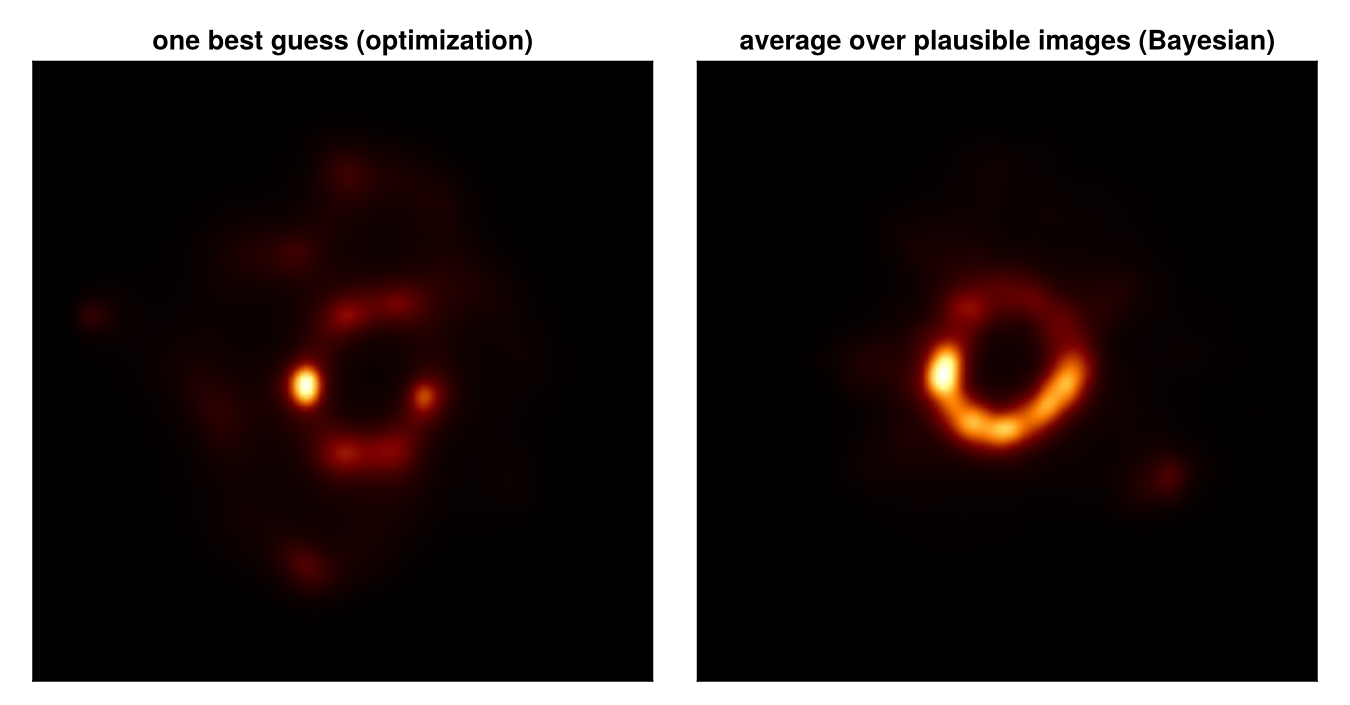

In [12]:
compare(xbest, imgs)

## Impulse: write the textbook model, the compiler makes it fast

Fast inference usually means rewriting the model by hand for performance. Impulse builds probabilistic programming into the compiler, so you write the model the way the textbook writes it and the compiler finds the rewrite.

**A real question:** do primates in bigger social groups have bigger brains? We have 151 species (model m14.10 from McElreath's *Statistical Rethinking*). The catch is that species are not independent data points: close relatives look alike because they share ancestry.

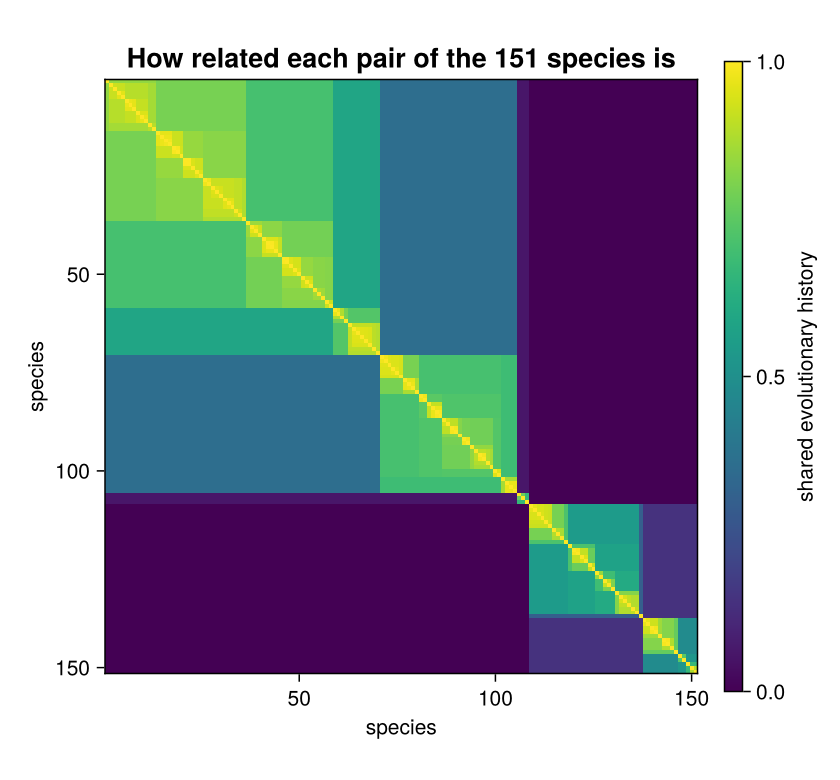

In [13]:
show_family_tree_matrix()

### The model, as the textbook writes it

The same few lines in every framework:

<table><tr><th>Impulse (Julia)</th><th>NumPyro (Python)</th><th>Turing (Julia)</th></tr><tr><td style="vertical-align:top"><pre style="font-size:12px">a  ~ Normal(0.0, 1.0)
bM ~ Normal(0.0, 0.5)
bG ~ Normal(0.0, 0.5)
sigma_sq ~ Exponential(1.0)

mu    = a .+ bM .* M .+ bG .* G
SIGMA = R .* sigma_sq

B ~ MvNormal(mu, SIGMA)</pre></td><td style="vertical-align:top"><pre style="font-size:12px">a  = numpyro.sample(&quot;a&quot;, dist.Normal(0.0, 1.0))
bM = numpyro.sample(&quot;bM&quot;, dist.Normal(0.0, 0.5))
bG = numpyro.sample(&quot;bG&quot;, dist.Normal(0.0, 0.5))
sigma_sq = numpyro.sample(&quot;sigma_sq&quot;, dist.Exponential(1.0))

mu    = a + bM * M + bG * G
SIGMA = R * sigma_sq

numpyro.sample(&quot;B&quot;, dist.MultivariateNormal(mu, SIGMA), obs=B)</pre></td><td style="vertical-align:top"><pre style="font-size:12px">a  ~ Normal(0.0, 1.0)
bM ~ Normal(0.0, 0.5)
bG ~ Normal(0.0, 0.5)
sigma_sq ~ Exponential(1.0)

mu    = a .+ bM .* M .+ bG .* G
SIGMA = R .* sigma_sq

B ~ MvNormal(mu, SIGMA)</pre></td></tr></table>

`SIGMA` is a 151 × 151 matrix. Every evaluation of the model does an expensive computation on `SIGMA`, and inference evaluates the model **thousands of times**.

### To make it fast, an expert rewrites it

`R` never changes, so an expert splits the computation and moves the expensive part out of the inference loop, to run **once**. Stan's documentation recommends exactly this rewrite:

<table><tr><th>textbook</th><th>expert rewrite</th></tr><tr><td style="vertical-align:top"><pre style="font-size:12px">model {
  ...
  SIGMA = R * sigma_sq;
  B ~ multi_normal(mu, SIGMA);
}</pre></td><td style="vertical-align:top"><pre style="font-size:12px">transformed data {
  matrix[N, N] L_R = cholesky_decompose(R);
}
model {
  ...
  B ~ multi_normal_cholesky(mu, sqrt(sigma_sq) * L_R);
}</pre></td></tr></table>

It takes linear-algebra insight, it is easy to get wrong, and the model no longer reads like the science.

### Live: Impulse runs the textbook code

Same model, same data, same sampler. The only difference is whether Impulse's compiler optimizations are on.

compiler optimizations OFF … 8.95 s for 1,000 warm-up + 3,000 posterior draws


compiler optimizations ON  … 0.46 s for 1,000 warm-up + 3,000 posterior draws


same code, 19× faster


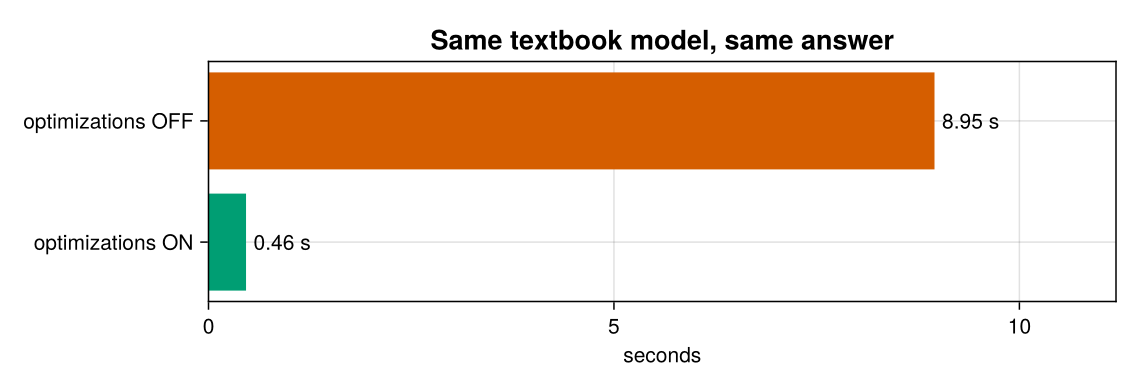

In [14]:
results, fig = race!()
fig

The compiler found the expert's rewrite by itself, **before any inference code existed**: it saw `cholesky(R * sigma_sq)`, rewrote it as `sqrt(sigma_sq) * cholesky(R)`, and moved `cholesky(R)` out of the loop because `R` never changes.

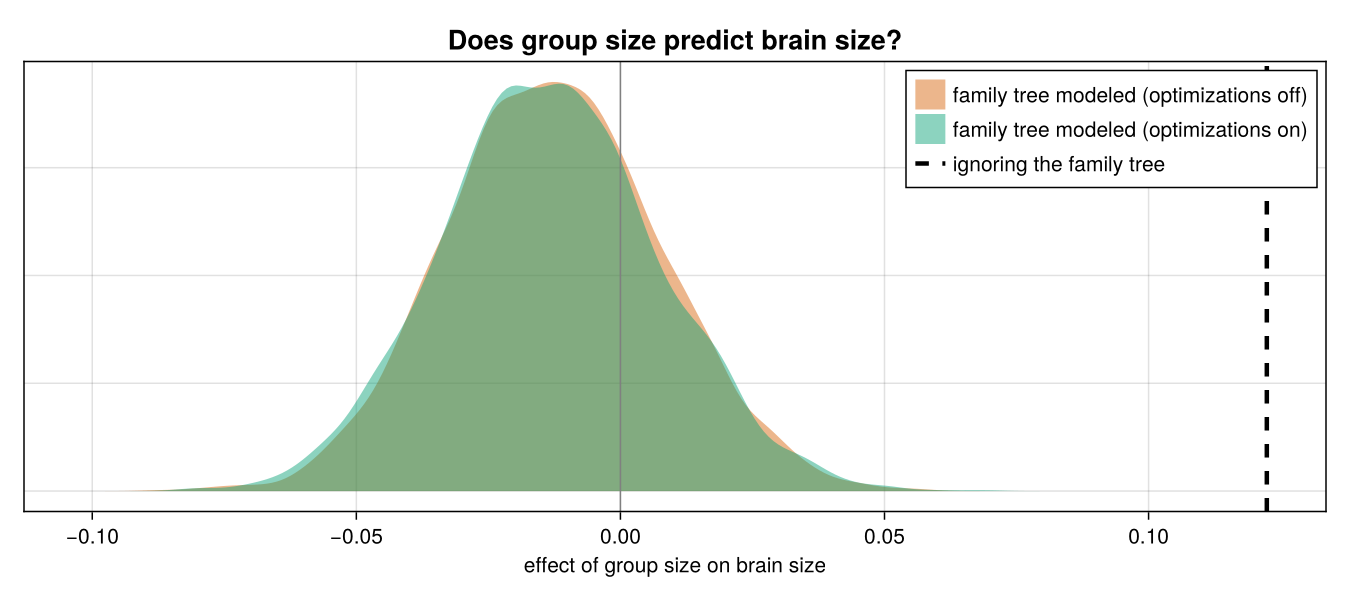

In [15]:
show_answer(results)

Treating species as independent, group size seems to matter. Once shared ancestry is modeled, the effect vanishes: the textbook's conclusion, reproduced in seconds, identical with optimizations on or off.

### Against other frameworks

The same textbook model in each framework, measured in our paper on one CPU core (1,000 warm-up + 3,000 draws). Every framework finds the same answer. NumPyro is built on JAX.

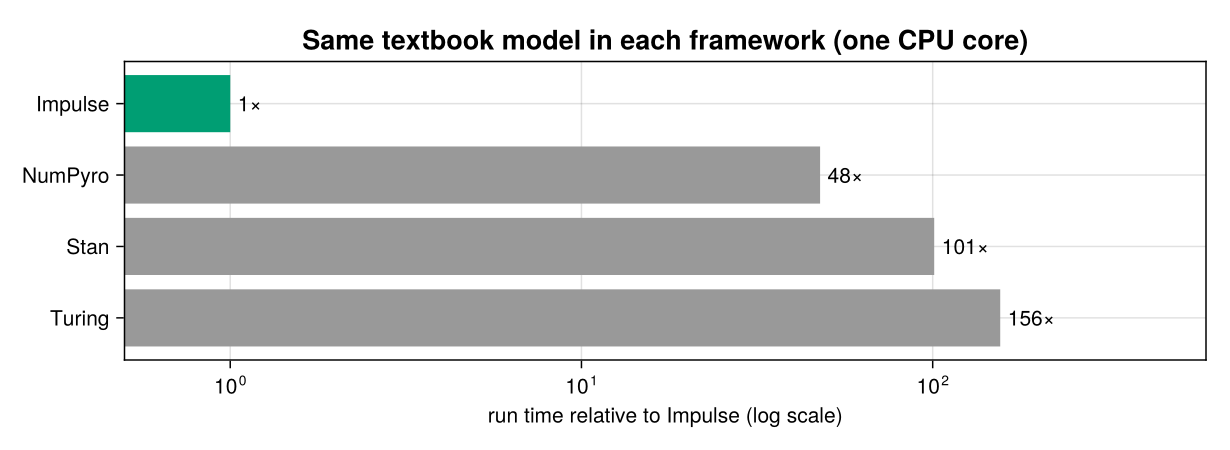

In [16]:
framework_bars()

**How it works.** Impulse makes sampling and inference part of the compiler, so the compiler optimizes the model itself before building the inference algorithm.

## What you saw

- **Reactant:** one line (`@jit`) runs existing code on a GPU, and the same compiler ran an ocean model written for NVIDIA GPUs on 1,280 Google TPUs.
- **Enzyme:** one line gives the gradient of an entire simulation, so the hidden pattern came back in about a second instead of millions of extra simulations.
- **Real science:** the EHT's imaging package, compiled, differentiated, and sampled with uncertainty, live.
- **Impulse:** the textbook model about 20× faster from the compiler alone, and 48×, 101× and 156× faster than NumPyro, Stan and Turing.

## Try it

```julia
] add Reactant Enzyme
using Reactant, Enzyme
x = Reactant.to_rarray(data)              # your data, on the GPU or TPU
@jit f(x)                                 # your function, compiled
@jit Enzyme.gradient(Reverse, f, x)       # its gradient
```

Bring us a model whose code is too slow, too hard to differentiate, or that needs uncertainty.

| | |
|---|---|
| Reactant.jl | https://github.com/EnzymeAD/Reactant.jl |
| Probabilistic programming (Impulse) tutorial | https://enzymead.github.io/Reactant.jl/stable/tutorials/probprog/ |
| Enzyme (C, C++, Fortran, Rust, Julia, Python/JAX, ...) | https://enzyme.mit.edu |
| Comrade.jl (black-hole imaging) | https://github.com/ptiede/Comrade.jl |
| BlackBoxComrade (EHT imaging pipeline) | https://github.com/BH-CAT/BlackBoxComrade.jl |
| Hands-on workshop notebook (Lux + Reactant) | https://colab.research.google.com/drive/1UobcFjfwDI3N2EXvH3KbRS5ZxY9Riy4y |